In [1]:
import pandas as pd
import numpy as np

data = pd.read_csv("./aice_restart_support.csv")

data.head()

,ticket_id,created_at,issue_type,contact_channel,membership_tier,tenure_months,monthly_spend,previous_tickets,wait_minutes,past_satisfaction_score,past_reopened_count,escalated
0,TK-00102,2026-01-25 10:00:00,Product,Phone,Basic,23,30400.0,2,14.9,2.6,0,Yes
1,TK-00433,2026-09-07 22:00:00,Payment,Chat,Basic,18,82400.0,1,18.0,NaN,0,No
2,TK-00310,2026-04-17 17:00:00,Delivery,Chat,Basic,11,186800.0,2,29.9,5.0,0,No
3,TK-00110,2026-04-15 22:00:00,Delivery,Chat,Silver,14,159600.0,5,26.0,2.9,2,No
4,TK-00653,2026-06-08 02:00:00,Technical,Chat,Gold,49,24600.0,2,10.8,2.8,0,No


In [2]:
# 행, 컬럼 갯수
print(data.shape)
# 각 컬럼별 non-null 개수 및 dtype
data.info()

(1210, 12)
<class 'pandas.DataFrame'>
RangeIndex: 1210 entries, 0 to 1209
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ticket_id                1210 non-null   str    
 1   created_at               1210 non-null   str    
 2   issue_type               1210 non-null   str    
 3   contact_channel          1186 non-null   str    
 4   membership_tier          1210 non-null   str    
 5   tenure_months            1210 non-null   int64  
 6   monthly_spend            1173 non-null   float64
 7   previous_tickets         1210 non-null   int64  
 8   wait_minutes             1150 non-null   float64
 9   past_satisfaction_score  1137 non-null   float64
 10  past_reopened_count      1210 non-null   int64  
 11  escalated                1202 non-null   str    
dtypes: float64(3), int64(3), str(6)
memory usage: 113.6 KB


In [3]:
# 컬럼별 결측치 개수
print(data.isna().sum())

# 완전히 동일한 중복 행 개수
print(data.duplicated().sum())

# 예측 대상의 개수 - 결측치도 함께 표시(dropna=False)
# value_counts() : 해당 컬럼의 분류마다의 갯수를 셈
print(data["escalated"].value_counts(dropna=False))

ticket_id                   0
created_at                  0
issue_type                  0
contact_channel            24
membership_tier             0
tenure_months               0
monthly_spend              37
previous_tickets            0
wait_minutes               60
past_satisfaction_score    73
past_reopened_count         0
escalated                   8
dtype: int64
10
escalated
No     982
Yes    220
NaN      8
Name: count, dtype: int64


In [4]:
# 완전히 동일한 중복 행 제거
data_clean = data.drop_duplicates().copy()

# 정답이 없는 행만 제거 (escalated 가 nan 인 곳)
data_clean = data_clean.dropna(subset=["escalated"])

# 인덱스를 0부터 다시 부여
data_clean = data_clean.reset_index(drop=True) # 기존 인덱스 버리고 다시 부여

In [5]:
print(data_clean.shape)
print(data_clean.duplicated().sum())
print(data_clean["escalated"].isna().sum())

(1192, 12)
0
0


In [6]:
# 문의 유형 합치기
# 두 유형에 해당하는 행 찾기 
mask = data_clean["issue_type"].isin(["Payment", "Account"])

# 해당 행의 문의 유형 변경
data_clean.loc[mask, "issue_type"] = "Account/Billing"

data_clean["issue_type"].value_counts()

issue_type
Account/Billing    445
Technical          284
Delivery           283
Product            180
Name: count, dtype: int64

In [7]:
# data_clean["escalated"] Yes, No 숫자로 변경
data_model = data_clean.copy()

data_model["escalated"] = data_model["escalated"].map({
    "No": 0,
    "Yes":1
})

data_model["escalated"].value_counts()

escalated
0    975
1    217
Name: count, dtype: int64

In [8]:
# 혹시 모를 결측치 확인
data_model["escalated"].isna().sum()

np.int64(0)

In [9]:
# 입력 데이터 X, 정답 데이터 y 나누기
X = data_model.drop(columns=["ticket_id", "created_at", "escalated"])
y = data_model["escalated"]

print(X.shape)
print(y.shape)
print(X.dtypes)

(1192, 9)
(1192,)
issue_type                     str
contact_channel                str
membership_tier                str
tenure_months                int64
monthly_spend              float64
previous_tickets             int64
wait_minutes               float64
past_satisfaction_score    float64
past_reopened_count          int64
dtype: object


In [10]:
# 테스트 데이터 나누기
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2, # 전체의 20%를 테스트용으로 분리
    random_state=42, # 같은 데이터와 설정으로 실행하면 같은 분할 재현
    stratify=y # 정답의 0과 1비율을 양쪽에 비슷하게 유지
)

print(X_train.shape)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True)) # 개수 대신 비율

(953, 9)
escalated
0    0.818468
1    0.181532
Name: proportion, dtype: float64
escalated
0    0.8159
1    0.1841
Name: proportion, dtype: float64


In [11]:
X_train.isna().sum()

issue_type                  0
contact_channel            16
membership_tier             0
tenure_months               0
monthly_spend              31
previous_tickets            0
wait_minutes               44
past_satisfaction_score    56
past_reopened_count         0
dtype: int64

In [12]:
# 수치형 컬럼의 결측치를 훈련 데이터의 중앙값으로 채우기
# 결측치가 있는 수치형 컬럼
numeric_columns = [
    "monthly_spend",
    "wait_minutes",
    "past_satisfaction_score"
]

# 훈련 데이터에서 컬럼별 중앙값 계산 
medians = X_train[numeric_columns].median()

# 양쪽 모두 같은 중앙값으로 채우기 
X_train[numeric_columns] = X_train[numeric_columns].fillna(medians)
X_test[numeric_columns] = X_test[numeric_columns].fillna(medians)

In [13]:
# 확인
print(X_train.isna().sum())
print(X_test.isna().sum())
print(medians)

issue_type                  0
contact_channel            16
membership_tier             0
tenure_months               0
monthly_spend               0
previous_tickets            0
wait_minutes                0
past_satisfaction_score     0
past_reopened_count         0
dtype: int64
issue_type                 0
contact_channel            8
membership_tier            0
tenure_months              0
monthly_spend              0
previous_tickets           0
wait_minutes               0
past_satisfaction_score    0
past_reopened_count        0
dtype: int64
monthly_spend              44300.0
wait_minutes                  22.5
past_satisfaction_score        3.5
dtype: float64


In [14]:
# 훈련 데이터에서 가장 자주 등장하는 값 선택(최빈값)
channel_mode = X_train["contact_channel"].mode().iloc[0]

channel_mode

'Chat'

In [15]:
X_train["contact_channel"] = X_train["contact_channel"].fillna(channel_mode)
X_test["contact_channel"] = X_test["contact_channel"].fillna(channel_mode)

print(X_train.isna().sum())
print(X_test.isna().sum())

issue_type                 0
contact_channel            0
membership_tier            0
tenure_months              0
monthly_spend              0
previous_tickets           0
wait_minutes               0
past_satisfaction_score    0
past_reopened_count        0
dtype: int64
issue_type                 0
contact_channel            0
membership_tier            0
tenure_months              0
monthly_spend              0
previous_tickets           0
wait_minutes               0
past_satisfaction_score    0
past_reopened_count        0
dtype: int64


In [16]:
# 문자형 원-핫 인코딩
X_train.info()

<class 'pandas.DataFrame'>
Index: 953 entries, 189 to 702
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   issue_type               953 non-null    str    
 1   contact_channel          953 non-null    str    
 2   membership_tier          953 non-null    str    
 3   tenure_months            953 non-null    int64  
 4   monthly_spend            953 non-null    float64
 5   previous_tickets         953 non-null    int64  
 6   wait_minutes             953 non-null    float64
 7   past_satisfaction_score  953 non-null    float64
 8   past_reopened_count      953 non-null    int64  
dtypes: float64(3), int64(3), str(3)
memory usage: 74.5 KB


In [17]:
categorical_columns = [
    "issue_type",
    "contact_channel",
    "membership_tier"
]

X_train = pd.get_dummies(
    X_train, columns=categorical_columns, dtype=int
)

X_test = pd.get_dummies(
    X_test, columns=categorical_columns, dtype=int
)

print(X_train.info())

<class 'pandas.DataFrame'>
Index: 953 entries, 189 to 702
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   tenure_months               953 non-null    int64  
 1   monthly_spend               953 non-null    float64
 2   previous_tickets            953 non-null    int64  
 3   wait_minutes                953 non-null    float64
 4   past_satisfaction_score     953 non-null    float64
 5   past_reopened_count         953 non-null    int64  
 6   issue_type_Account/Billing  953 non-null    int64  
 7   issue_type_Delivery         953 non-null    int64  
 8   issue_type_Product          953 non-null    int64  
 9   issue_type_Technical        953 non-null    int64  
 10  contact_channel_Chat        953 non-null    int64  
 11  contact_channel_Email       953 non-null    int64  
 12  contact_channel_Phone       953 non-null    int64  
 13  membership_tier_Basic       953 non-null    int64

In [18]:
print(X_test.info())

<class 'pandas.DataFrame'>
Index: 239 entries, 1063 to 66
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   tenure_months               239 non-null    int64  
 1   monthly_spend               239 non-null    float64
 2   previous_tickets            239 non-null    int64  
 3   wait_minutes                239 non-null    float64
 4   past_satisfaction_score     239 non-null    float64
 5   past_reopened_count         239 non-null    int64  
 6   issue_type_Account/Billing  239 non-null    int64  
 7   issue_type_Delivery         239 non-null    int64  
 8   issue_type_Product          239 non-null    int64  
 9   issue_type_Technical        239 non-null    int64  
 10  contact_channel_Chat        239 non-null    int64  
 11  contact_channel_Email       239 non-null    int64  
 12  contact_channel_Phone       239 non-null    int64  
 13  membership_tier_Basic       239 non-null    int64

In [19]:
# 컬럼이 일치하는지 확인
X_train.columns.equals(X_test.columns)

True

In [20]:
# 분리된 데이터를 각각 인코딩하면 한쪽에만 있는 범주 때문에 컬럼이 달라질 수 있음. 테스트 컬럼을 훈련 컬럼 기준으로 맞추기
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
X_train.columns.equals(X_test.columns)

True

In [21]:
# 스케일링으로 입력값의 단위를 맞춤 
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train) # 훈련 데이터의 평균, 표준 편차를 구하고 반환
X_test_scaled = scaler.transform(X_test) # 훈련에서 구한 기준으로 테스트 데이터를 반환

print(X_train_scaled.shape)
print(X_test_scaled.shape)

(953, 16)
(239, 16)


In [22]:
print(X_train_scaled.mean(axis=0).round(3))

[-0. -0.  0.  0.  0.  0. -0. -0. -0.  0.  0.  0.  0.  0.  0.  0.]


In [23]:
# 로지스틱 회귀 모델(0,1 구분)
from sklearn.linear_model import LogisticRegression

# max_+iter = 학습 계산의 최대 반복 횟수 
lr = LogisticRegression(max_iter=1000, random_state=42)

# 훈련 데이터와 정답으로 학습(입력, 정답)
lr.fit(X_train_scaled, y_train)

# 테스트 데이터의 클래스 예측(입력)
y_pred = lr.predict(X_test_scaled)

print(f"예측{y_pred[:10]}")
print(f"실제{y_test.iloc[:10].to_numpy()}")

예측[0 0 0 0 0 0 0 0 0 0]
실제[0 0 0 0 0 0 1 0 0 0]


In [24]:
# 혼동행렬
#      0                          1
# 0 TN:실제 음성=음성           FP:실제 음성을 양성으로 잘못
# 1 FN:실제 양성을 음성으로 잘못 TP:실제 양성=양성
# Precision = TP / (TP + FP) : 모델이 1이라고 예측한 것 중 실제로 1인 비율(정밀도)
# Recall = TP / (TP + FN) : 실제로 1인 것 중 모델이 1로 찾아낸 비율(재현율)
from sklearn.metrics import confusion_matrix, classification_report

print("혼동행렬:")
print(confusion_matrix(y_test, y_pred))

print("\n분류 평가:")
print(classification_report(y_test, y_pred, zero_division=0)) # 분모가 0이면 그 지표를 0으로 표시하라


혼동행렬:
[[192   3]
 [ 35   9]]

분류 평가:
              precision    recall  f1-score   support

           0       0.85      0.98      0.91       195
           1       0.75      0.20      0.32        44

    accuracy                           0.84       239
   macro avg       0.80      0.59      0.62       239
weighted avg       0.83      0.84      0.80       239



In [25]:
# 불균형 고려해서 모델 학습
# 1을 놓치는 비용이 크면 balanced 쪽이 유리하고, 잘못된 정보를 줄이는 게 중요하면 기본 모델이 유리
lr_balanced = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight="balanced"
)

lr_balanced.fit(X_train_scaled, y_train)

y_pred_balanced = lr_balanced.predict(X_test_scaled)

print(confusion_matrix(y_test, y_pred_balanced))
print(classification_report(y_test, y_pred_balanced, zero_division=0))

[[145  50]
 [ 19  25]]
              precision    recall  f1-score   support

           0       0.88      0.74      0.81       195
           1       0.33      0.57      0.42        44

    accuracy                           0.71       239
   macro avg       0.61      0.66      0.61       239
weighted avg       0.78      0.71      0.74       239



In [26]:
y_proba = lr_balanced.predict_proba(X_test_scaled)

print(f"클래스 순서 : {lr_balanced.classes_}") 
print(y_proba[:10]) # 각각 0일 확률, 1일 확률

클래스 순서 : [0 1]
[[0.76171251 0.23828749]
 [0.63738644 0.36261356]
 [0.88524484 0.11475516]
 [0.67404504 0.32595496]
 [0.7840801  0.2159199 ]
 [0.58582034 0.41417966]
 [0.60659753 0.39340247]
 [0.53018417 0.46981583]
 [0.50598121 0.49401879]
 [0.50758864 0.49241136]]


In [27]:
# 클래스 1일 확률만 추출 
y_proba_1 = y_proba[:,1] # 모든 행에서 1번 열 번호는 0번부터
print(y_proba_1[:10])

[0.23828749 0.36261356 0.11475516 0.32595496 0.2159199  0.41417966
 0.39340247 0.46981583 0.49401879 0.49241136]


In [28]:
from sklearn.metrics import roc_auc_score

print(f"ROC-AUC:{roc_auc_score(y_test, y_proba_1)}") # roc-auc는 실제 1인 사례에 실제 0인 사례보다 높은 점수를 주는 능력 평가

ROC-AUC:0.7255244755244755


In [29]:
# 랜덤 포레스트 분류
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    class_weight="balanced",
    random_state=42
)

# 스케일링 되지 않은 데이터 
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)[:,1]

print(confusion_matrix(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf, zero_division=0))
print(roc_auc_score(y_test, y_proba_rf))

[[153  42]
 [ 22  22]]
              precision    recall  f1-score   support

           0       0.87      0.78      0.83       195
           1       0.34      0.50      0.41        44

    accuracy                           0.73       239
   macro avg       0.61      0.64      0.62       239
weighted avg       0.78      0.73      0.75       239

0.6994172494172494


In [ ]:
# 랜덤 포레스트 변수 중요도
importance = pd.DataFrame({
    "feature" : X_train.columns, # 학습에 사용한 변수 이름
    "importance" : rf.feature_importances_ # 각 변수의 중요도
})

importance = importance.sort_values(
    "importance", ascending=False
)

print(importance.head(10))

                    feature  importance
4   past_satisfaction_score    0.276344
3              wait_minutes    0.199560
2          previous_tickets    0.146030
1             monthly_spend    0.104152
0             tenure_months    0.096679
5       past_reopened_count    0.065714
9      issue_type_Technical    0.020342
13    membership_tier_Basic    0.016982
14     membership_tier_Gold    0.013370
7       issue_type_Delivery    0.011369


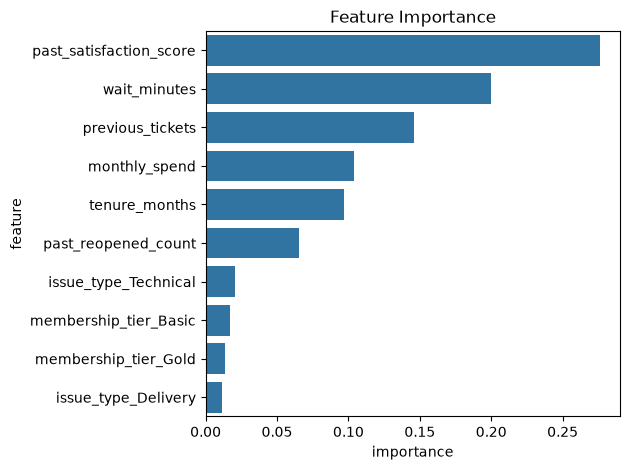

In [ ]:
import matplotlib.pyplot as plt 
import seaborn as sns

sns.barplot(
    data=importance.head(10),
    x="importance", # 중요도 
    y="feature" # 변수명
)

plt.title("Feature Importance")
plt.tight_layout()
plt.show()

In [33]:
# 딥러닝
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout

model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)), # 한 행의 입력 특성
    Dense(32, activation="relu"), # 입력에서 패턴을 학습하는 층
    Dropout(0.2), # 학습 중 입력받은 값을 무작위로 약 20% 꺼서 과적합을 줄임
    Dense(16, activation="relu"), 
    Dense(1, activation="sigmoid") # 클래스 1일 확률을 숫자 하나로 출력 (정답이 0 or 1인 이진분류라 출력 노드 1개, 활성화 함수 sigmoid)
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,089 (4.25 KB)

 Trainable params: 1,089 (4.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# 모델 컴파일 
model.compile(
    optimizer="adam", # 학습 중 가중치를 조정하는 방법
    loss="binary_crossentropy", # 정답이 0,1인 이진 분류의 손실 함수
    metrics=["accuracy"] # 학습 중 확인할 평가 지표
)

# 기존 훈련 데이터 20%를 검증용으로 분리
# fit : 가중치를 실제로 학습
# valid : 학습 중 성능 확인, 최적 시점 선택
X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_train_scaled, # 학습이 끝난뒤 최종평가 1
    y_train, # 학습이 끝난 뒤 최종평가 2
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print(X_fit.shape, X_valid.shape)

(762, 16) (191, 16)


In [35]:
# 조기 종료와 최적 모델 저장을 설정 및 학습
# 가중치 복원은 메모리에서, 체크포인트 저장은 파일로
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

estop = EarlyStopping(
    monitor="val_loss", # 검증 손실을 기준으로 판단(낮을수록 좋음)
    patience=8, # 검증 손실이 8 epoch 연속 개선되지 않으면 종료
    restore_best_weights=True # 종료 후 메모리 속 모델을 최적 가중치로 복원
)

checkpoint = ModelCheckpoint(
    filepath="best_support_model.keras",
    monitor="val_loss",
    save_best_only=True # 검증 손실이 가장 좋아질 때만 파일에 저장
)

# 학습
history = model.fit(
    X_fit,
    y_fit,
    validation_data=(X_valid, y_valid),
    epochs=80,
    batch_size=32,
    callbacks=[estop, checkpoint]
)

print(f"실제 학습 ephoch 수 : { len(history.epoch)}")


Epoch 1/80
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.6365 - loss: 0.6423 - val_accuracy: 0.7958 - val_loss: 0.5358
Epoch 2/80
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7940 - loss: 0.5267 - val_accuracy: 0.8220 - val_loss: 0.4802
Epoch 3/80
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8123 - loss: 0.4741 - val_accuracy: 0.8168 - val_loss: 0.4597
Epoch 4/80
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8202 - loss: 0.4629 - val_accuracy: 0.8168 - val_loss: 0.4423
Epoch 5/80
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8202 - loss: 0.4594 - val_accuracy: 0.8168 - val_loss: 0.4310
Epoch 6/80
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8202 - loss: 0.4450 - val_accuracy: 0.8168 - val_loss: 0.4203
Epoch 7/80
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8176 - loss: 0.4328 - val_accuracy: 0.8168 - val_loss: 0.4112
Epoch 8/80
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8202 - loss: 0.4395 - val_accuracy: 0.8220 - val_loss:

In [36]:
# 저장된 최적 모델 불러오기
from tensorflow.keras.models import load_model

best_model = load_model("best_support_model.keras")

# evaluate() -> 입력과 정답을 함께 줘야함 (예측과 실제 정답을 비교해 손실, 정확도를 계산하기 때문.)
test_loss, test_accuracy = best_model.evaluate(
    X_test_scaled, 
    y_test,
    verbose=0
)

print(test_loss)
print(test_accuracy)

0.4259739816188812
0.8326359987258911


In [ ]:
# 클래스 1일 확률을 예측하고 1차원으로 변환
y_proba_dl = best_model.predict(X_test_scaled, verbose=0).ravel()

# 확률이 0.5 이상이면 1, 아니면 0
y_pred_dl = (y_proba_dl >= 0.5).astype(int)

print(confusion_matrix(y_test, y_pred_dl))
print(classification_report(y_test, y_pred_dl, zero_division=0))
print(roc_auc_score(y_test, y_proba_dl)) # 노드 하나일 때는 argmax 안씀


[[191   4]
 [ 36   8]]
              precision    recall  f1-score   support

           0       0.84      0.98      0.91       195
           1       0.67      0.18      0.29        44

    accuracy                           0.83       239
   macro avg       0.75      0.58      0.60       239
weighted avg       0.81      0.83      0.79       239

0.7222610722610723


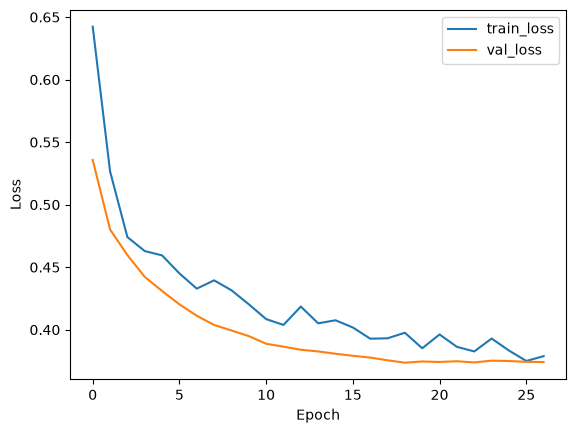

In [39]:
plt.plot(history.history["loss"], label="train_loss")
plt.plot(history.history["val_loss"], label="val_loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [ ]:
# 클래스 1일 확률을 예측하고 1차원으로 변환
y_proba_dl = best_model.predict(X_test_scaled, verbose=0).ravel()

# 확률이 0.5 이상이면 1, 아니면 0
y_pred_dl = (y_proba_dl >= 0.5).astype(int)

print(confusion_matrix(y_test, y_pred_dl))
print(classification_report(y_test, y_pred_dl, zero_division=0))
print(roc_auc_score(y_test, y_proba_dl))

[[191   4]
 [ 36   8]]
              precision    recall  f1-score   support

           0       0.84      0.98      0.91       195
           1       0.67      0.18      0.29        44

    accuracy                           0.83       239
   macro avg       0.75      0.58      0.60       239
weighted avg       0.81      0.83      0.79       239

0.7222610722610723


In [40]:
# 검증 손실이 가장 낮은 epoch
best_epoch = np.argmin(history.history["val_loss"]) + 1

print(best_epoch)

19
